# Distributed Systems and Architecture Patterns for AI Engineers

> **Who is this for:** AI engineers who can build a model service or a RAG app on one machine, and now need to run it on many machines without it breaking in strange ways. Also useful for system design interviews.
>
> **What you will learn:**
> - why "many computers" is harder than "one computer": partial failures, slow networks, and **clocks that lie** (Lamport and vector clocks)
> - **consensus** and **leader election** in simple words (Raft: terms, elections, log replication), with a runnable simulation that crashes the leader
> - **distributed locks**: leases, **fencing tokens**, and why **Redlock** is debated (runnable demo of a paused client corrupting data)
> - reliable multi-step work: **sagas** (orchestration vs choreography), the **transactional outbox**, **CQRS** and **event sourcing**
> - how services find and talk to each other: **service discovery**, **sidecars / service mesh**, **API gateway vs backend-for-frontend (BFF)**
> - **migration patterns**: the **strangler fig** (runnable router that moves endpoints from an old model API to a new one)
> - data spread: **consistent hashing** with virtual nodes (runnable), hot keys, cache invalidation, rate limiting across nodes
> - **multi-region** and **active-active** set-ups
> - **Infrastructure as Code** (Terraform, Pulumi, CloudFormation/CDK): declarative state, plan/apply, drift, modules, remote state and locking, with a runnable toy "plan/apply/drift" engine
>
> **Prerequisites:** [System design fundamentals](../23_Software_Engineering/09_system_design_fundamentals.ipynb) (load balancing, caching, replication, quorums, queues, rate limiting). Helpful: [distributed databases](../13_Databases/00_dbms_fundamentals/09_distributed_databases_warehousing_and_security.ipynb), [message queues](../16_Deployment/message_queues/01_message_queues.ipynb), [Helm and GitOps](../17_Docker/03_helm_and_gitops.ipynb).
>
> **Time needed:** about 2-3 hours to read and play (the code runs in a few seconds).
>
> **Runs on:** CPU, no API key, no internet. Everything is plain Python toys (standard library, numpy, pandas, matplotlib). The "services", "cloud" and "clusters" are small Python objects that stand in for the real thing.

## Explained simply

Imagine a group of friends planning a trip over text messages. Messages arrive late or not at all, one friend's phone dies, and everyone's phone clock shows a slightly different time. Still, the group must agree on **one** plan, avoid two people booking the same hotel, and undo bookings if the trip is cancelled.

That is a distributed system: several computers that can only talk by sending messages over a network that can be slow or broken. This notebook is a toolbox of the standard patterns people use to make such a group behave like one reliable machine.

### How this notebook relates to others in the repo

Many basics are already taught in depth elsewhere. We **link** to them instead of repeating them, and only add what is missing.

| Topic | Already taught in depth in | What this notebook adds |
|---|---|---|
| Back-of-envelope numbers, load balancing, caching patterns, replication, quorums (N/R/W), sharding and hot keys, CAP/PACELC, queues, idempotency keys, delivery guarantees, 5 rate-limit algorithms, circuit breakers, bulkheads | [23_Software_Engineering/09_system_design_fundamentals](../23_Software_Engineering/09_system_design_fundamentals.ipynb) | a short AI-flavoured recap only; rate limiting **across nodes** |
| Paxos/Raft (one paragraph), 2PC/3PC, CAP, consistent hashing | [13_Databases/.../09_distributed_databases_warehousing_and_security](../13_Databases/00_dbms_fundamentals/09_distributed_databases_warehousing_and_security.ipynb) | Raft **mechanics** with a runnable election simulation |
| Kafka, Celery, Redis Streams | [16_Deployment/message_queues/01_message_queues](../16_Deployment/message_queues/01_message_queues.ipynb) | outbox relay, sagas, event sourcing |
| Exactly-once, checkpoints, Chandy-Lamport snapshots | [13_Databases/06_data_engineering/04_stream_processing_from_scratch](../13_Databases/06_data_engineering/04_stream_processing_from_scratch.ipynb) | clocks (Lamport, vector) |
| Shadow, canary, blue-green, A/B, feature flags | [16_Deployment/05_industry_safe_model_rollout_strategies](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb) | strangler fig migration, multi-region |
| Helm, GitOps, ArgoCD, Flux | [17_Docker/03_helm_and_gitops](../17_Docker/03_helm_and_gitops.ipynb) | Infrastructure as Code (Terraform, Pulumi, CDK) |
| Kubernetes objects | [17_Docker/kubernetes/01_kubernetes](../17_Docker/kubernetes/01_kubernetes.ipynb) | service discovery, sidecars, leader election with Lease objects |
| Back-of-envelope for an ML system, failure modes | [22_ML_System_Design/08_industry_system_design_case_study](08_industry_system_design_case_study.ipynb) | one LLM-serving estimate |
| Model gateway, retries, fallbacks for LLM apps | [22_ML_System_Design/09_ai_system_design_for_llm_applications](09_ai_system_design_for_llm_applications.ipynb) | API gateway vs BFF |

### Contents

0. Setup
1. Why distributed systems are hard (and why clocks lie)
2. Consensus and leader election (Raft)
3. Distributed locks, leases and fencing tokens
4. Reliable multi-step work: sagas and the outbox
5. CQRS and event sourcing
6. How services find and talk to each other
7. Migration patterns: strangler fig and BFF
8. Spreading data and load
9. Multi-region and active-active
10. Infrastructure as Code
11. Back-of-envelope estimation for an AI system
12. Recap
13. Interview questions
14. Further reading

## 0. Setup

Only the standard library plus numpy, pandas and matplotlib. A fixed random seed makes every run print the same thing.

In [1]:
import random, hashlib, bisect, sqlite3, json, copy     # standard library helpers
from collections import Counter, defaultdict
import numpy as np                                       # numbers
import pandas as pd                                      # tables
import matplotlib.pyplot as plt                          # small plots

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 120)

def h64(text):
    """A stable 64-bit hash of a string (Python's built-in hash() changes between runs)."""
    return int(hashlib.md5(text.encode()).hexdigest()[:16], 16)

print("ready")

ready


## 1. Why distributed systems are hard (and why clocks lie)

A **distributed system** is a set of computers (called **nodes**) that work together by sending messages over a network.

Three things make it hard:

1. **Partial failure.** On one laptop, a program either works or crashes. With 10 nodes, node 3 may be dead, node 7 slow, and the link between 2 and 5 broken, all at once. You often cannot tell "dead" from "slow".
2. **Unreliable messages.** A message can be delayed, lost, duplicated, or arrive out of order. If you get no reply, you do not know whether the request was processed.
3. **No shared clock.** Each node has its own clock, and the clocks disagree.

A famous list, the **fallacies of distributed computing** (from engineers at Sun Microsystems in the 1990s), sums up the false beliefs: "the network is reliable", "latency is zero", "bandwidth is infinite", "the network is secure", "topology does not change", "there is one administrator", "transport cost is zero", "the network is homogeneous".

**A process pause** is when a program stops running for a while without knowing it: a garbage-collection pause, the virtual machine being moved, the laptop lid closing, a long page-fault storm. Pauses of seconds happen in practice. Keep this in mind: it is the villain of section 3.

### 1.1 Wall clocks lie

**What it is:** a **wall clock** is the normal "time of day" clock (`time.time()`). Each machine keeps its own, and they drift apart. NTP (Network Time Protocol) pulls them back together, but can be off by milliseconds or more, and can even jump **backwards**.

**Simple analogy:** two friends with watches that are a few minutes apart arguing about who arrived first.

**Why it matters:** "last write wins by timestamp" can silently keep the **older** value. Below, node A's clock runs 2 seconds slow. A user edits a system prompt on node B, then a moment later edits it again on node A. The later edit gets the smaller timestamp and is thrown away.

In [2]:
# Real order of events (true time in seconds): first B writes, then A writes 1 second later.
clock_skew = {"A": -2.0, "B": 0.0}          # node A's wall clock is 2 s behind
true_events = [(100.0, "B", "prompt v1: 'You are a helpful assistant.'"),
               (101.0, "A", "prompt v2: 'You are a helpful, concise assistant.'")]

stored = None
for true_t, node, value in true_events:
    wall_ts = true_t + clock_skew[node]       # the timestamp the node writes down
    print(f"node {node} writes {value!r:55} with wall-clock ts={wall_ts}")
    if stored is None or wall_ts > stored[0]:  # last-write-wins by timestamp
        stored = (wall_ts, value)

print("\nkept by last-write-wins:", stored[1])
print("but the newest edit was:  ", true_events[-1][2])

node B writes "prompt v1: 'You are a helpful assistant.'"             with wall-clock ts=100.0
node A writes "prompt v2: 'You are a helpful, concise assistant.'"    with wall-clock ts=99.0

kept by last-write-wins: prompt v1: 'You are a helpful assistant.'
but the newest edit was:   prompt v2: 'You are a helpful, concise assistant.'


**What just happened?** The newest edit lost because node A's clock was behind. Nothing crashed and no error was logged. This is why careful systems do not trust wall clocks for ordering. Use them for humans ("this log line was at about 10:02") and for timeouts with generous margins, not for "which happened first".

Two common tools instead:

- **Monotonic clocks** (`time.monotonic()`) only go forward. Good for measuring durations on **one** machine (timeouts, leases). Useless for comparing across machines.
- **Logical clocks** (below) count events instead of seconds.

(Google Spanner takes a third route: special hardware clocks plus an explicit uncertainty interval called TrueTime. Most teams do not have that.)

### 1.2 Lamport clocks

**What it is:** a **Lamport clock** (Leslie Lamport, 1978) is a counter on each node. It gives every event a number so that if event X **could have caused** event Y, then X gets a smaller number.

**Simple analogy:** a "take a number" ticket that you also stamp on every letter you send. Whoever reads your letter moves their own counter past your number.

**How it works:**
1. Before each local event, add 1 to your counter.
2. When you send a message, attach your counter.
3. When you receive a message, set your counter to `max(mine, theirs) + 1`.

In [3]:
class LamportClock:
    def __init__(self, name):
        self.name, self.t = name, 0
    def local(self, what):
        self.t += 1
        print(f"  {self.name}: t={self.t:<2} {what}")
    def send(self, what):
        self.t += 1
        print(f"  {self.name}: t={self.t:<2} send  '{what}'")
        return self.t                              # the timestamp travels with the message
    def receive(self, msg_t, what):
        self.t = max(self.t, msg_t) + 1
        print(f"  {self.name}: t={self.t:<2} recv  '{what}' (msg had t={msg_t})")

api, worker = LamportClock("api   "), LamportClock("worker")
api.local("user uploads a document")
m = api.send("embed doc 17")
worker.local("finishes an unrelated job")
worker.local("finishes another job")
worker.receive(m, "embed doc 17")
m2 = worker.send("doc 17 embedded")
api.receive(m2, "doc 17 embedded")

  api   : t=1  user uploads a document
  api   : t=2  send  'embed doc 17'
  worker: t=1  finishes an unrelated job
  worker: t=2  finishes another job
  worker: t=3  recv  'embed doc 17' (msg had t=2)
  worker: t=4  send  'doc 17 embedded'
  api   : t=5  recv  'doc 17 embedded' (msg had t=4)


**What just happened?** "Send" always has a smaller number than its matching "receive", even though the worker's counter was ahead. Sort by Lamport time and you get an order that respects cause and effect.

**Limit:** a smaller Lamport number does **not** prove one event caused the other. Two unrelated events still get different numbers. To **detect** that two events are unrelated ("concurrent"), you need vector clocks.

### 1.3 Vector clocks

**What it is:** a **vector clock** is one counter **per node**, carried together. Comparing two vectors tells you "A happened before B", "B happened before A", or "they are **concurrent**" (neither knew about the other). Concurrent writes are a **conflict** the application must resolve.

**How it works:** a node adds 1 to its own entry on each update. When it learns about another version, it takes the element-wise maximum. X happened before Y if every entry of X is `<=` the matching entry of Y (and at least one is smaller).

In [4]:
def compare(vc_a, vc_b):
    """Return 'before', 'after', 'equal' or 'CONCURRENT' for two vector clocks (dicts node -> count)."""
    nodes = set(vc_a) | set(vc_b)
    a_le_b = all(vc_a.get(n, 0) <= vc_b.get(n, 0) for n in nodes)
    b_le_a = all(vc_b.get(n, 0) <= vc_a.get(n, 0) for n in nodes)
    if a_le_b and b_le_a: return "equal"
    if a_le_b: return "before"
    if b_le_a: return "after"
    return "CONCURRENT"

v0 = {"eu": 1, "us": 0}            # prompt template created in the EU region
v1 = {"eu": 2, "us": 0}            # EU edits it again (knew about v0)
v2 = {"eu": 1, "us": 1}            # meanwhile US edits v0 (did NOT see v1)
print("v0 vs v1:", compare(v0, v1))
print("v1 vs v2:", compare(v1, v2), " <- two regions edited at the same time: keep both, ask or merge")
merged = {n: max(v1.get(n, 0), v2.get(n, 0)) for n in set(v1) | set(v2)}
merged["eu"] += 1                  # the merge is a new write by the EU node
print("after merge:", merged, "| merged vs v1:", compare(merged, v1), "| merged vs v2:", compare(merged, v2))

v0 vs v1: before
v1 vs v2: CONCURRENT  <- two regions edited at the same time: keep both, ask or merge
after merge: {'eu': 3, 'us': 1} | merged vs v1: after | merged vs v2: after


**When to use which:**

| Need | Tool |
|---|---|
| measure a timeout or a lease on one machine | monotonic clock |
| show a time to humans | wall clock |
| a total order that respects cause and effect (logs, event IDs) | Lamport clock, or a hybrid logical clock (HLC: wall time plus a counter, used by CockroachDB and others) |
| detect conflicting concurrent writes (multi-region, offline edits) | vector clocks (Dynamo-style stores), or CRDTs (data types that merge automatically) |
| one agreed order of all writes | consensus (next section) |

## 2. Consensus and leader election (Raft)

### 2.1 What and why

**Consensus** means several nodes agree on a value (or on a sequence of values) even if some of them crash. **Leader election** is the most common use: the nodes agree on **one** node that is in charge.

**Simple analogy:** a team picks one captain who makes the calls. If the captain goes silent, the team quickly votes for a new one. A vote needs a **majority**, so two halves of a split team can never both pick a captain.

**Why AI systems need it:**
- **One GPU scheduler leader.** You run 3 replicas of your training-job scheduler for availability, but only one may hand out GPUs, or two jobs land on the same GPU.
- One node runs the nightly re-embedding cron job, one node compacts the vector index, one node owns a Kafka partition.
- Kubernetes itself: its scheduler and controller manager run several copies and elect a leader through **Lease** objects; its database **etcd** uses Raft.

**Do not build this yourself.** Use **etcd**, **ZooKeeper**, **Consul**, or the Kubernetes Lease API (client libraries have a ready "leader election" helper). We simulate Raft only to understand what those tools do for you.

### 2.2 Raft in simple words

**Raft** (Diego Ongaro and John Ousterhout, 2014) was designed to be easier to understand than the older **Paxos**. Every node is in one of three states:

```mermaid
flowchart LR
    F[Follower] -- "no heartbeat before my<br/>random election timeout" --> C[Candidate]
    C -- "got votes from a majority" --> L[Leader]
    C -- "timeout again (split vote)" --> C
    C -- "saw a leader or a higher term" --> F
    L -- "saw a higher term" --> F
```

- **Term:** a numbered "election period" (1, 2, 3, ...). Each term has at most one leader. Terms act like a logical clock: a node that sees a higher term immediately accepts it and steps down if it was leader.
- **Heartbeats:** the leader sends small messages every ~50 ms meaning "I am alive".
- **Election timeout:** each follower waits a **random** time (the Raft paper suggests 150-300 ms). If no heartbeat arrives in time, it becomes a **candidate**: it adds 1 to the term, votes for itself, and asks everyone else for votes.
- **Voting rule:** each node gives **one vote per term**, first come first served (plus a safety check: never vote for a candidate whose log is behind yours).
- **Majority wins:** with 5 nodes, 3 votes are needed. So a cluster of 5 survives 2 crashes; a cluster of 3 survives 1. This is why clusters have odd sizes.
- **Why random timeouts?** If all followers time out at the same moment, they all vote for themselves and nobody wins (a **split vote**). Randomness makes one node almost always wake up first.

### 2.3 A runnable election simulation

Time moves in 10 ms steps. Messages arrive in the next step. We crash the leader at 1,000 ms and bring it back at 1,600 ms, still believing it is the leader.

In [5]:
class RaftNode:
    def __init__(self, nid, rng, randomized):
        self.id, self.rng, self.randomized = nid, rng, randomized
        self.term, self.voted_for, self.state, self.alive = 0, None, "follower", True
    def reset_timer(self, now):
        timeout = self.rng.randint(150, 300) if self.randomized else 200   # ms
        self.deadline = now + timeout
    def see_term(self, term, now, log, t):
        """Raft rule: if someone has a higher term, adopt it and become a follower."""
        if term > self.term:
            if self.state == "leader":
                log.append((t, f"node {self.id} sees term {term} > its term {self.term}: steps down"))
            self.term, self.voted_for, self.state = term, None, "follower"

In [6]:
def run_cluster(n=5, until=2400, crash_at=None, restart_at=None, randomized=True, seed=SEED):
    rng = random.Random(seed)
    nodes = [RaftNode(i, rng, randomized) for i in range(n)]
    for x in nodes: x.reset_timer(0)
    log, crashed, leader_ms = [], None, 0
    for now in range(0, until, 10):
        live = [x for x in nodes if x.alive]
        leaders = [x for x in live if x.state == "leader"]
        # ---- failure injection
        if now == crash_at and leaders:
            crashed = leaders[0]; crashed.alive = False
            log.append((now, f"node {crashed.id} CRASHES (it was leader of term {crashed.term})"))
        if now == restart_at and crashed:
            crashed.alive = True; crashed.reset_timer(now)
            log.append((now, f"node {crashed.id} comes back, still thinks it is leader of term {crashed.term}"))
        live = [x for x in nodes if x.alive]
        # ---- leaders send heartbeats every 50 ms
        for ldr in [x for x in live if x.state == "leader"]:
            if now % 50 == 0:
                for p in live:
                    if p is ldr: continue
                    ldr.see_term(p.term, now, log, now)          # reply carries the follower's term
                    if ldr.state != "leader": break
                    p.see_term(ldr.term, now, log, now)
                    if p.term == ldr.term:
                        p.state = "follower"; p.reset_timer(now)
        # ---- phase 1: followers whose timer expired become candidates
        cands = [x for x in live if x.state != "leader" and now >= x.deadline]
        for c in cands:
            c.term += 1; c.state = "candidate"; c.voted_for = c.id; c.reset_timer(now)
            log.append((now, f"node {c.id} times out, starts election for term {c.term}"))
        # ---- phase 2: vote requests are delivered
        for c in cands:
            if c.state != "candidate": continue
            votes = 1
            for p in live:
                if p is c: continue
                p.see_term(c.term, now, log, now)
                if p.term == c.term and p.voted_for in (None, c.id):
                    p.voted_for = c.id; votes += 1; p.reset_timer(now)
            if votes > n // 2:
                c.state = "leader"
                log.append((now, f"node {c.id} WINS term {c.term} with {votes}/{n} votes"))
            else:
                log.append((now, f"node {c.id} got only {votes}/{n} votes (split vote)"))
        leader_ms += 10 if any(x.alive and x.state == "leader" for x in nodes) else 0
    return log, leader_ms / until

In [7]:
log, up = run_cluster(crash_at=1000, restart_at=1600, randomized=True)
for t, event in log:
    print(f"{t:>5} ms  {event}")
print(f"\na leader existed {up:.0%} of the time")

  160 ms  node 1 times out, starts election for term 1
  160 ms  node 1 WINS term 1 with 5/5 votes
 1000 ms  node 1 CRASHES (it was leader of term 1)
 1150 ms  node 2 times out, starts election for term 2
 1150 ms  node 2 WINS term 2 with 4/5 votes
 1600 ms  node 1 comes back, still thinks it is leader of term 1
 1600 ms  node 1 sees term 2 > its term 1: steps down

a leader existed 87% of the time


**What just happened?**
- At the start nobody is leader. The node with the shortest random timeout asks first, gets a majority and becomes leader of term 1.
- When the leader crashes, followers stop getting heartbeats. One times out first, starts term 2, and wins. The gap without a leader is about 150 ms here: this is the **failover time**, and it is set by the election timeout (plus how long the dead leader's last heartbeat stays fresh).
- The old leader comes back still believing it leads term 1. The first reply it gets shows a higher term, so it **steps down**. Terms stop an old leader from causing damage **inside the cluster**. (Outside the cluster, for example a storage system that does not know about terms, you still need **fencing tokens**: see section 3.)

Now the same cluster with **fixed** timeouts: everyone wakes at the same moment, votes for themselves, and nobody wins, again and again.

In [8]:
log_fixed, up_fixed = run_cluster(until=1000, randomized=False)
for t, event in log_fixed[:7]:
    print(f"{t:>5} ms  {event}")
print("   ...")
splits = sum("split vote" in e for _, e in log_fixed)
print(f"\nfixed timeouts: {splits} split votes, a leader existed {up_fixed:.0%} of the time")

  200 ms  node 0 times out, starts election for term 1
  200 ms  node 1 times out, starts election for term 1
  200 ms  node 2 times out, starts election for term 1
  200 ms  node 3 times out, starts election for term 1
  200 ms  node 4 times out, starts election for term 1
  200 ms  node 0 got only 1/5 votes (split vote)
  200 ms  node 1 got only 1/5 votes (split vote)
   ...

fixed timeouts: 20 split votes, a leader existed 0% of the time


### 2.4 Log replication in one picture

Electing a leader is half of Raft. The other half is keeping the same **log** (an ordered list of commands, like "assign GPU 3 to job A") on every node.

1. Clients send commands **only to the leader**.
2. The leader appends the command to its log and sends it to the followers (the same message as the heartbeat, called *AppendEntries*).
3. When a **majority** has stored it, the entry is **committed**: it will never be lost, even if the leader dies now. The leader applies it and replies to the client.
4. A follower that was down or slow gets the missing entries later. The leader also checks the entry just before the new ones (index and term) so a follower with a different history gets its wrong tail replaced.

In [9]:
N = 5
leader_log, follower_logs = [], {1: [], 2: [], 3: [], 4: []}
down = {4}                                   # follower 4 is offline for now

def leader_append(cmd, term=2):
    leader_log.append((term, cmd))
    acks = 1                                 # the leader itself
    for f, flog in follower_logs.items():
        if f in down: continue
        flog[:] = leader_log[:]              # simplified AppendEntries: copy what is missing
        acks += 1
    status = "COMMITTED" if acks > N // 2 else "not committed yet"
    print(f"{cmd:32} stored on {acks}/{N} nodes -> {status}")

leader_append("assign gpu-3 to job A")
down |= {3, 2}                               # now only leader + follower 1 are reachable
leader_append("assign gpu-5 to job B")
down = set()                                 # network heals
leader_append("release gpu-3")
print("follower 4 log after catching up:", [c for _, c in follower_logs[4]])

assign gpu-3 to job A            stored on 4/5 nodes -> COMMITTED
assign gpu-5 to job B            stored on 2/5 nodes -> not committed yet
release gpu-3                    stored on 5/5 nodes -> COMMITTED
follower 4 log after catching up: ['assign gpu-3 to job A', 'assign gpu-5 to job B', 'release gpu-3']


**What just happened?** The second command reached only 2 of 5 nodes, so it was **not** committed and the client would not get "OK" yet. When the network healed, the next round copied everything, including the entry follower 4 missed. In real Raft the leader keeps retrying until the second command is on a majority.

**When to use consensus / when not to:**

| Use it for | Do not use it for |
|---|---|
| small, critical metadata: who is leader, cluster membership, config, which shard lives where, lock ownership | bulk data (embeddings, logs, model weights): every write costs a majority round trip |
| a single scheduler / cron owner among replicas | anything where "two workers at once" is harmless: just make the work idempotent instead |

## 3. Distributed locks, leases and fencing tokens

### 3.1 What and why

**What it is:** a **distributed lock** makes sure only one process, on any machine, does something at a time.

**Simple analogy:** the single key to the meeting room hanging at reception.

**AI example:** a **lock around vector index rebuilds**. Rebuilding an HNSW index for 50 million chunks takes an hour. If two workers rebuild at once, you waste GPU hours, or worse, both write the "active index" pointer and the older build wins.

### 3.2 Leases

A lock held by a crashed process would be stuck forever. So distributed locks are **leases**: a lock that **expires** after a time-to-live (TTL), for example 10 seconds. The holder must renew it before it expires. If the holder dies, the lease runs out and someone else can take over.

That fixes crashes, but creates a new problem: **a holder that is paused, not dead**. It stops for 15 seconds (a garbage-collection pause, say), its lease expires, another worker takes the lock, and then the first one wakes up and carries on, believing it still holds the lock. Checking "do I still hold it?" right before writing does not help: the pause can happen **between** the check and the write.

### 3.3 Fencing tokens

**What it is:** every time the lock service grants the lock, it also hands out a **fencing token**: a number that goes up by one each time (33, 34, 35, ...). The holder sends the token with every write. The **storage** remembers the highest token it has seen and **rejects** writes with a smaller one.

**Simple analogy:** a deli ticket number. Once the counter has served number 34, someone waving ticket 33 is turned away.

The demo: a fake clock, a lease-lock service, and a storage that can check fencing tokens or not.

In [10]:
class FakeClock:
    def __init__(self): self.now = 0.0          # seconds

class LeaseLock:
    """A lock service that grants leases with a TTL and a fencing token that always increases."""
    def __init__(self, clock, ttl):
        self.clock, self.ttl = clock, ttl
        self.holder, self.expires, self.token = None, 0.0, 32
    def acquire(self, who):
        if self.holder is None or self.clock.now >= self.expires:   # free, or the old lease expired
            self.token += 1
            self.holder, self.expires = who, self.clock.now + self.ttl
            return self.token
        return None                                                 # someone else holds it

class IndexStore:
    """Stores which vector index is 'active'. Optionally checks fencing tokens."""
    def __init__(self, check_fencing):
        self.check, self.max_token, self.active = check_fencing, 0, "index_v6"
    def write(self, value, token):
        if self.check and token < self.max_token:
            return f"REJECTED (token {token} < highest seen {self.max_token})"
        self.max_token = max(self.max_token, token)
        self.active = value
        return "ok"

In [11]:
def scenario(check_fencing):
    clock = FakeClock(); lock = LeaseLock(clock, ttl=10); store = IndexStore(check_fencing)
    say = lambda msg: print(f"  t={clock.now:>4.0f}s  {msg}")
    tok_a = lock.acquire("worker-A"); say(f"worker-A gets the lock, token={tok_a}, starts rebuilding index_v7")
    clock.now = 2;  say("worker-A pauses (long garbage-collection pause)...")
    clock.now = 11; tok_b = lock.acquire("worker-B")
    say(f"lease expired; worker-B gets the lock, token={tok_b}, builds the newer index_v8")
    clock.now = 14; say(f"worker-B writes active=index_v8 -> {store.write('index_v8', tok_b)}")
    clock.now = 17; say(f"worker-A wakes up, still thinks it holds the lock, writes active=index_v7 -> {store.write('index_v7', tok_a)}")
    print(f"  FINAL active index = {store.active}\n")

print("WITHOUT fencing tokens:"); scenario(check_fencing=False)
print("WITH fencing tokens:");    scenario(check_fencing=True)

WITHOUT fencing tokens:
  t=   0s  worker-A gets the lock, token=33, starts rebuilding index_v7
  t=   2s  worker-A pauses (long garbage-collection pause)...
  t=  11s  lease expired; worker-B gets the lock, token=34, builds the newer index_v8
  t=  14s  worker-B writes active=index_v8 -> ok
  t=  17s  worker-A wakes up, still thinks it holds the lock, writes active=index_v7 -> ok
  FINAL active index = index_v7

WITH fencing tokens:
  t=   0s  worker-A gets the lock, token=33, starts rebuilding index_v7
  t=   2s  worker-A pauses (long garbage-collection pause)...
  t=  11s  lease expired; worker-B gets the lock, token=34, builds the newer index_v8
  t=  14s  worker-B writes active=index_v8 -> ok
  t=  17s  worker-A wakes up, still thinks it holds the lock, writes active=index_v7 -> REJECTED (token 33 < highest seen 34)
  FINAL active index = index_v8



**What just happened?** Without fencing, the paused worker overwrote the newer index with an older one: silent data corruption. With fencing, the storage rejected the stale token. Notice **the storage does the check**, not the client. The client cannot be trusted to know it was paused.

In real systems: etcd gives a revision number with each lease, ZooKeeper has node version numbers (zxid), and a database can do the same with a conditional write such as `UPDATE ... SET active=?, token=? WHERE token < ?`.

### 3.4 Why Redlock is debated

**Redlock** is an algorithm proposed by the Redis author (Salvatore Sanfilippo, "antirez") for locks across several independent Redis servers: take the lock on a majority (say 3 of 5) within a short time, and treat it as valid for the TTL minus the time spent.

In 2016 Martin Kleppmann wrote "How to do distributed locking", arguing that Redlock is not safe enough **for correctness**:
- It does not produce a **fencing token**, so the paused-client problem above is not solved.
- Its safety depends on **timing assumptions** (bounded network delay, bounded process pauses, clocks that do not jump). Real systems break these assumptions sometimes.

antirez replied ("Is Redlock safe?") defending the design under its stated assumptions. The debate is still a classic interview topic. The practical takeaway many engineers draw:

| Why you lock | What happens if two holders overlap | Reasonable choice |
|---|---|---|
| **Efficiency** (avoid doing the same work twice, for example two workers re-embedding the same file) | a bit of wasted compute | a single Redis `SET key value NX PX 10000` lock is fine |
| **Correctness** (two holders would corrupt data, double-assign a GPU, double-charge a customer) | wrong data | a consensus-backed lock (etcd, ZooKeeper, Consul) **plus fencing tokens** checked by the storage, or avoid the lock with a conditional write / transaction in the database itself |

**When not to use a distributed lock at all:** if the work can be made **idempotent** (doing it twice gives the same result) or the database can do an atomic compare-and-set, prefer that. Locks add a dependency and a failure mode.

## 4. Reliable multi-step work: sagas and the outbox

Quick recap (taught in depth in [system design fundamentals, section 5](../23_Software_Engineering/09_system_design_fundamentals.ipynb)):
- **At-most-once:** a message may be lost, never duplicated. **At-least-once:** never lost, may be duplicated (the normal choice). **Exactly-once** end-to-end over an unreliable network is not possible in general; what you build is **effectively-once = at-least-once delivery + an idempotent handler**.
- An **idempotency key** is a unique ID per logical operation (for example `Idempotency-Key: 6f1c...` on a "start fine-tune job" request) so a retried request is recognised and not run twice.

Now two patterns that build on these.

### 4.1 Sagas

**What it is:** a **saga** (Garcia-Molina and Salem, 1987) is a long business operation split into steps, where each step has an **undo** called a **compensating action**. If step 4 fails, you run the undos of steps 3, 2, 1 in reverse order.

**Simple analogy:** booking a trip: flight, then hotel, then car. If no car is available, you cancel the hotel and the flight. You cannot "roll back time", but you can cancel.

**Why not one big transaction?** The steps live in different services with different databases (billing, GPU quota, storage). A cross-service transaction (two-phase commit, see the [distributed databases notebook](../13_Databases/00_dbms_fundamentals/09_distributed_databases_warehousing_and_security.ipynb)) blocks everyone if the coordinator dies and many services (and most SaaS APIs) do not support it.

**Two styles:**

| | Orchestration | Choreography |
|---|---|---|
| How | one **orchestrator** service calls each step and runs compensations on failure | each service listens for events and emits its own ("QuotaReserved" -> storage copies data -> "DatasetReady" -> ...) |
| Pros | flow is in one place, easy to see and test | no central component, services loosely coupled |
| Cons | the orchestrator is extra code to run | flow is spread out, hard to follow and debug with many steps |
| Good for | 4+ steps, AI pipelines, anything you must explain to auditors | 2-3 steps between teams that already share an event bus |
| Tools | Temporal, AWS Step Functions, Airflow-like workflow engines, LangGraph for agent flows | Kafka / a message bus |

```mermaid
flowchart LR
    subgraph Orchestration
    O[Fine-tune orchestrator] --> Q1[Quota service]
    O --> S1[Storage]
    O --> B1[Billing]
    O --> T1[Training cluster]
    end
    subgraph Choreography
    Q2[Quota] -- QuotaReserved --> S2[Storage]
    S2 -- DatasetReady --> B2[Billing]
    B2 -- Charged --> T2[Training]
    T2 -- LaunchFailed --> B2
    end
```

**AI example (orchestration):** "start a fine-tuning job" = reserve GPU quota -> snapshot the dataset -> charge credits -> launch training.

In [12]:
class SagaStep:
    def __init__(self, name, action, compensate):
        self.name, self.action, self.compensate = name, action, compensate

def run_saga(steps, ctx):
    done = []
    for step in steps:
        try:
            step.action(ctx); done.append(step); print(f"  ok      {step.name}")
        except Exception as err:
            print(f"  FAILED  {step.name}: {err}")
            for prev in reversed(done):               # undo in reverse order
                prev.compensate(ctx); print(f"  undo    {prev.name}")
            return "rolled back"
    return "completed"

def launch(ctx):
    if not ctx["gpus_ready"]: raise RuntimeError("no GPU nodes ready in region")
    ctx["job"] = "ft-job-881"

steps = [
    SagaStep("reserve 8 GPUs of quota", lambda c: c.update(quota=c["quota"] - 8), lambda c: c.update(quota=c["quota"] + 8)),
    SagaStep("snapshot dataset",        lambda c: c.update(snapshot="snap-17"),   lambda c: c.update(snapshot=None)),
    SagaStep("charge 120 credits",      lambda c: c.update(credits=c["credits"] - 120), lambda c: c.update(credits=c["credits"] + 120)),
    SagaStep("launch training job",     launch,                                   lambda c: c.update(job=None)),
]
for ready in (True, False):
    ctx = {"quota": 32, "credits": 500, "snapshot": None, "job": None, "gpus_ready": ready}
    print(f"GPUs ready = {ready}:")
    print("  result:", run_saga(steps, ctx), "| state:", {k: ctx[k] for k in ("quota", "credits", "snapshot", "job")}, "\n")

GPUs ready = True:
  ok      reserve 8 GPUs of quota
  ok      snapshot dataset
  ok      charge 120 credits
  ok      launch training job
  result: completed | state: {'quota': 24, 'credits': 380, 'snapshot': 'snap-17', 'job': 'ft-job-881'} 

GPUs ready = False:
  ok      reserve 8 GPUs of quota
  ok      snapshot dataset
  ok      charge 120 credits
  FAILED  launch training job: no GPU nodes ready in region
  undo    charge 120 credits
  undo    snapshot dataset
  undo    reserve 8 GPUs of quota
  result: rolled back | state: {'quota': 32, 'credits': 500, 'snapshot': None, 'job': None} 



**What just happened?** When launching failed, the saga refunded the credits, deleted the snapshot and released the quota. The final state is the same as before the request.

Things to remember:
- Compensations must themselves be **retried until they succeed**, and be **idempotent** (refunding twice must not pay twice; use the idempotency key).
- Between steps, other users can see the half-done state (credits charged, job not running). Sagas give up **isolation**. Design the UI for it ("job is starting...").
- Some actions cannot be undone (an email sent, an LLM call already paid for). Put them **last**, or compensate with a follow-up action ("sorry, ignore the previous email").

### 4.2 The transactional outbox

**The problem (dual write):** your service saves a document to its database **and** publishes "DocumentAdded" to a queue, so a worker can embed it for RAG. Two separate writes: if the process dies between them, the document exists but is **never indexed**, and nobody notices.

**What it is:** the **outbox pattern** writes the event into an `outbox` table **in the same database transaction** as the business change. A separate **relay** process reads the outbox and publishes to the queue, marking rows as sent.

**Simple analogy:** instead of writing a letter and then hoping you remember to post it, you drop it in the office out-tray as part of finishing the task. The mail clerk empties the out-tray.

```mermaid
flowchart LR
    API[Upload API] -- "one DB transaction" --> DB[(documents + outbox)]
    R[Outbox relay] -- "poll unsent rows" --> DB
    R -- publish --> MQ[[Queue]]
    MQ --> W[Embedding worker<br/>dedupes by event_id]
```

First the naive version, where the publish fails after the database commit:

In [13]:
def fresh_db():
    db = sqlite3.connect(":memory:")
    db.execute("CREATE TABLE documents (id TEXT PRIMARY KEY, body TEXT)")
    db.execute("CREATE TABLE outbox (event_id INTEGER PRIMARY KEY AUTOINCREMENT, topic TEXT, payload TEXT, sent INTEGER DEFAULT 0)")
    return db

# Naive dual write: save, then publish. The broker is down for the second upload.
db, queue = fresh_db(), []
for doc_id, broker_up in [("doc-1", True), ("doc-2", False)]:
    with db: db.execute("INSERT INTO documents VALUES (?, ?)", (doc_id, "some text"))
    if broker_up: queue.append(doc_id)
    else: print(f"  publish for {doc_id} failed (broker down) and the process moves on")
saved = [r[0] for r in db.execute("SELECT id FROM documents")]
print("saved:", saved, "| queued for embedding:", queue, "-> doc-2 will never be searchable")

  publish for doc-2 failed (broker down) and the process moves on
saved: ['doc-1', 'doc-2'] | queued for embedding: ['doc-1'] -> doc-2 will never be searchable


In [14]:
db, queue = fresh_db(), []

def add_document(doc_id, body):
    with db:                                         # ONE transaction: both rows or neither
        db.execute("INSERT INTO documents VALUES (?, ?)", (doc_id, body))
        db.execute("INSERT INTO outbox (topic, payload) VALUES (?, ?)",
                   ("DocumentAdded", json.dumps({"doc_id": doc_id})))

def relay_once(crash_before_marking=False):
    rows = db.execute("SELECT event_id, topic, payload FROM outbox WHERE sent = 0 ORDER BY event_id").fetchall()
    for event_id, topic, payload in rows:
        queue.append({"event_id": event_id, "topic": topic, **json.loads(payload)})   # publish
        if crash_before_marking:
            print(f"  relay crashed after publishing event {event_id}, before marking it sent")
            return
        with db: db.execute("UPDATE outbox SET sent = 1 WHERE event_id = ?", (event_id,))

add_document("doc-1", "refund policy ...")
add_document("doc-2", "shipping times ...")
relay_once(crash_before_marking=True)   # publishes event 1, then dies
relay_once()                            # restarted relay publishes 1 again, then 2
print("messages on the queue:", [m["event_id"] for m in queue])

  relay crashed after publishing event 1, before marking it sent
messages on the queue: [1, 1, 2]


In [15]:
# The consumer is idempotent: it remembers which event_ids it already processed.
processed, index = set(), []
for msg in queue:
    if msg["event_id"] in processed:
        print(f"  skip duplicate event {msg['event_id']}"); continue
    index.append(msg["doc_id"])          # stand-in for "embed and upsert into the vector DB"
    processed.add(msg["event_id"])
print("documents in the vector index:", index)

  skip duplicate event 1
documents in the vector index: ['doc-1', 'doc-2']


**What just happened?** The outbox gave us **at-least-once** publishing: nothing is lost, even when the relay crashes, but event 1 was published twice. The consumer's dedupe by `event_id` turned that into **effectively-once**. In production, the `processed` set lives in the consumer's database and is updated in the same transaction as the effect (or the upsert is naturally idempotent, like "upsert vector for doc-1").

Instead of polling, relays often use **change data capture (CDC)**: a tool such as Debezium reads the database's write-ahead log and streams outbox rows to Kafka.

**When to use:** any time a database change must reliably trigger something elsewhere (indexing, notifications, billing). **When not to:** if losing an occasional event is fine (analytics counters), a direct publish is simpler.

## 5. CQRS and event sourcing

These two are often used together but are separate ideas.

### 5.1 CQRS

**What it is:** **Command Query Responsibility Segregation** means using **different models for writing and for reading**. Commands ("promote model v7 to production") go to a write model that checks rules. Queries ("show the dashboard of all models and their stages") read from one or more **read models** (also called projections or views) that are shaped for fast reading.

**Simple analogy:** a restaurant kitchen takes orders on tickets (write side), while the menu board out front (read side) is updated from those tickets and is shaped for customers, not cooks.

**When to use:** reads and writes look very different or scale very differently (millions of reads of a leaderboard, few writes), or you need several views of the same data (search index, analytics table, cache). **When not to:** a normal CRUD app. CQRS adds moving parts and the read side is usually **eventually consistent** (a bit behind).

### 5.2 Event sourcing

**What it is:** instead of storing only the **current state** ("model v7 is in production"), you store the full list of **events** that happened ("v7 registered", "v7 moved to staging", "v7 promoted", "v7 rolled back"). Current state is computed by replaying events.

**Simple analogy:** a bank account statement. The balance is just the sum of all transactions, and you can always explain how you got there.

**AI example:** a **model registry**. Auditors (and the EU AI Act style regulations) want to know which model was serving on which date, and who changed it. With event sourcing, that history is the data itself.

In [16]:
# The event store: append-only. Nothing is ever updated or deleted.
events = [
    {"seq": 1, "day": 1, "type": "ModelRegistered", "model": "ranker", "version": 6, "by": "ci"},
    {"seq": 2, "day": 1, "type": "StageChanged",    "model": "ranker", "version": 6, "stage": "production", "by": "alice"},
    {"seq": 3, "day": 5, "type": "ModelRegistered", "model": "ranker", "version": 7, "by": "ci"},
    {"seq": 4, "day": 6, "type": "StageChanged",    "model": "ranker", "version": 7, "stage": "production", "by": "bob"},
    {"seq": 5, "day": 6, "type": "StageChanged",    "model": "ranker", "version": 6, "stage": "archived",   "by": "bob"},
    {"seq": 6, "day": 8, "type": "StageChanged",    "model": "ranker", "version": 7, "stage": "rolled_back","by": "alice"},
    {"seq": 7, "day": 8, "type": "StageChanged",    "model": "ranker", "version": 6, "stage": "production", "by": "alice"},
]

def project_current_stage(evts, up_to_day=None):
    """Read model 1: current stage of each version (a projection built by replaying events)."""
    stage = {}
    for e in evts:
        if up_to_day is not None and e["day"] > up_to_day: break
        if e["type"] == "ModelRegistered": stage[e["version"]] = "registered"
        if e["type"] == "StageChanged":    stage[e["version"]] = e["stage"]
    return stage

print("now:           ", project_current_stage(events))
print("as of day 7:   ", project_current_stage(events, up_to_day=7), " <- 'time travel' for free")
audit = pd.DataFrame([e for e in events if e["type"] == "StageChanged"])[["day", "version", "stage", "by"]]
print("\nread model 2: audit trail\n", audit.to_string(index=False))

now:            {6: 'production', 7: 'rolled_back'}
as of day 7:    {6: 'archived', 7: 'production'}  <- 'time travel' for free

read model 2: audit trail
  day  version       stage    by
   1        6  production alice
   6        7  production   bob
   6        6    archived   bob
   8        7 rolled_back alice
   8        6  production alice


**What just happened?** One append-only list fed two read models: "current stage" and "audit trail". We also answered "what was in production on day 7?" without any extra table. Adding a new view later (for example "average days in staging") is just another replay.

**Costs of event sourcing:** replaying millions of events is slow (fix: periodic **snapshots**); changing an event's shape later needs **versioning/upcasting**; deleting personal data (GDPR) is hard in an append-only log (fix: keep personal data outside the events, or encrypt it per user and throw away the key). Use it where history matters (registries, billing, agent action logs), not everywhere.

## 6. How services find and talk to each other

### 6.1 Service discovery

**What it is:** in the cloud, instances come and go and change IP addresses. **Service discovery** is how a client finds the current, healthy addresses of a service ("where are the `embedding-service` replicas right now?").

**Simple analogy:** a phone directory that updates itself and removes people who have not answered in a while.

**How it works:**
- A **service registry** (Consul, etcd, ZooKeeper, Eureka, or Kubernetes' own API) keeps a list of instances.
- Instances **register** and send **heartbeats**; an entry is a lease with a TTL, so a crashed instance disappears by itself (the same lease idea as section 3).
- **Client-side discovery:** the client asks the registry and picks an instance itself. **Server-side discovery:** the client calls one stable name (a load balancer or a Kubernetes **Service**, reached through cluster DNS like `embedding-service.default.svc.cluster.local`), which forwards to a healthy instance.

In [17]:
class Registry:
    def __init__(self, ttl): self.ttl, self.entries = ttl, {}       # (service, addr) -> last heartbeat time
    def heartbeat(self, service, addr, now): self.entries[(service, addr)] = now
    def lookup(self, service, now):
        return sorted(a for (s, a), t in self.entries.items() if s == service and now - t < self.ttl)

reg = Registry(ttl=10)
for now in range(0, 31, 5):
    for addr in ("10.0.0.11", "10.0.0.12", "10.0.0.13"):
        if addr == "10.0.0.12" and now >= 10: continue               # this GPU worker crashed at t=10
        reg.heartbeat("gpu-inference", addr, now)
    print(f"t={now:>2}s  healthy gpu-inference replicas: {reg.lookup('gpu-inference', now)}")

t= 0s  healthy gpu-inference replicas: ['10.0.0.11', '10.0.0.12', '10.0.0.13']
t= 5s  healthy gpu-inference replicas: ['10.0.0.11', '10.0.0.12', '10.0.0.13']
t=10s  healthy gpu-inference replicas: ['10.0.0.11', '10.0.0.12', '10.0.0.13']
t=15s  healthy gpu-inference replicas: ['10.0.0.11', '10.0.0.13']
t=20s  healthy gpu-inference replicas: ['10.0.0.11', '10.0.0.13']
t=25s  healthy gpu-inference replicas: ['10.0.0.11', '10.0.0.13']
t=30s  healthy gpu-inference replicas: ['10.0.0.11', '10.0.0.13']


**What just happened?** The crashed replica sent its last heartbeat at t=5, was still listed at t=10 (clients would still send it traffic), and vanished once a full TTL had passed (t=15). Short TTLs mean faster removal but more heartbeat traffic; clients should still retry on another replica if a call fails.

### 6.2 Sidecars and service mesh

**What it is:** a **sidecar** is a helper process that runs **next to** your service (in Kubernetes: a second container in the same pod) and handles plumbing so your code does not have to: TLS, retries, metrics, log shipping. A **service mesh** (Istio, Linkerd, Consul Connect; usually built on the Envoy proxy) is many such proxies plus a control plane that configures them all.

**Simple analogy:** a motorbike sidecar that carries the luggage, so the rider just rides.

**What a mesh gives you:** mutual TLS between every service (each side proves who it is), retries/timeouts/circuit breaking by config, traffic splitting for canaries, and uniform metrics and traces, all without changing application code.

**When not to:** a handful of services. A mesh adds latency (an extra hop per call), memory per pod, and a complex system to operate. As of late 2026 some meshes also offer "sidecar-less" modes that move the proxy to each node instead of each pod, to cut that cost.

**AI example:** an LLM-serving pod with the model server container plus a sidecar that enforces mTLS and exports token-usage metrics; or a sidecar that downloads model weights before the server starts (an "init container").

### 6.3 API gateway vs backend-for-frontend (BFF)

**API gateway:** one entry point in front of all services that does the shared jobs: authentication, rate limits, routing, TLS, request logging. (Its LLM-specific cousin, the "model gateway", is in [notebook 09](09_ai_system_design_for_llm_applications.ipynb).)

**Backend-for-frontend (BFF):** a **separate small backend per kind of client**, owned by the team that builds that client. Each BFF calls the shared services and shapes the answer for its client. The term was popularised by Sam Newman.

**Simple analogy:** the gateway is the building's front desk (checks badges for everyone). A BFF is a personal assistant for each department who knows exactly what that department needs and fetches it.

**AI example:** a **chat UI** needs streaming tokens over SSE, short answers, conversation history and citations formatted for display. A **batch client** (nightly classification of a million tickets) needs a bulk job API, no streaming, large payloads, and different rate limits. One generic API serves both badly. Two BFFs, both calling the same model and retrieval services, serve each well.

```mermaid
flowchart LR
    W[Chat web app] --> G[API gateway<br/>auth, rate limits, TLS]
    M[Mobile app] --> G
    B[Batch client] --> G
    G --> BW[Chat BFF<br/>SSE streaming, history, citations]
    G --> BM[Mobile BFF<br/>smaller payloads]
    G --> BB[Batch BFF<br/>bulk jobs, webhooks]
    BW --> S1[Model service]
    BM --> S1
    BB --> S1
    BW --> S2[Retrieval service]
    BB --> S2
```

| | API gateway | BFF |
|---|---|---|
| How many | usually one (per environment) | one per client type |
| Does | cross-cutting concerns: auth, quotas, routing, TLS | client-specific shaping: aggregation, formatting, streaming style |
| Owned by | platform team | the client's team |
| Risk | becomes a "god" layer if business logic creeps in | duplicated logic across BFFs; keep shared logic in services |
| Use together? | yes: gateway in front, BFFs behind it | |

## 7. Migration patterns: strangler fig and BFF

### 7.1 Strangler fig

**What it is:** a way to replace an old system **gradually**. Put a routing layer (a "facade") in front of the old system. Move one feature at a time to the new system, and send a growing share of traffic for that feature to it. When nothing is left on the old system, switch it off. Martin Fowler named it after the strangler fig tree, which grows around a host tree until it replaces it.

**Simple analogy:** renovating a house one room at a time while still living in it, instead of moving out and rebuilding everything.

**Why not a "big bang" rewrite?** One huge switch-over day means one huge risk, months without user feedback, and a frozen old system. The strangler fig lets you ship, measure and roll back one piece at a time.

**AI example:** you have a 2021-era monolith "`/v1` model API" (in-house BERT classifier, old summarizer). You want a new service backed by an LLM gateway, with new evals and logging. Migrate endpoint by endpoint, by percentage of users.

```mermaid
flowchart LR
    C[Clients] --> R{Strangler router<br/>per-endpoint %}
    R -- "/summarize 100%" --> N[New model service]
    R -- "/classify 30%" --> N
    R -- "/classify 70%, /embed 100%" --> L[Legacy model API]
```

How it works, step by step:
1. Put the router in front, sending 100% to legacy (no behaviour change yet).
2. Build the new endpoint. Optionally **shadow** it first (copy traffic, compare outputs, do not return them; see [rollout strategies](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb)).
3. Raise the share: 1% -> 10% -> 50% -> 100%, watching errors, latency, cost and quality evals. Roll back by lowering the number.
4. Repeat per endpoint. When all are at 100%, delete the legacy code.

Users are assigned by a **hash of their user ID**, so each user consistently sees the same backend, and raising the share only moves users from old to new, never back and forth.

In [18]:
def legacy_api(endpoint, user): return f"legacy:{endpoint}"
def new_api(endpoint, user):    return f"new:{endpoint}"

class StranglerRouter:
    def __init__(self): self.share_new = {}                  # endpoint -> % of users on the new service
    def bucket(self, user): return h64(f"strangler:{user}") % 100   # stable 0..99 per user
    def route(self, endpoint, user):
        target = new_api if self.bucket(user) < self.share_new.get(endpoint, 0) else legacy_api
        return target(endpoint, user)

router = StranglerRouter()
users = [f"user{i}" for i in range(2000)]
endpoints = ["/summarize", "/classify", "/embed"]
plan = [  # migration stages: % of users sent to the new service per endpoint
    ("week 1", {"/summarize": 10}),
    ("week 2", {"/summarize": 50, "/classify": 5}),
    ("week 3", {"/summarize": 100, "/classify": 30}),
    ("week 5", {"/summarize": 100, "/classify": 100, "/embed": 50}),
    ("week 6", {"/summarize": 100, "/classify": 100, "/embed": 100}),
]
rows, previous = [], {}
for stage, shares in plan:
    router.share_new = shares
    row = {"stage": stage}
    for ep in endpoints:
        on_new = {u for u in users if router.route(ep, u).startswith("new")}
        row[ep] = f"{len(on_new) / len(users):.0%}"
        moved_back = previous.get(ep, set()) - on_new      # users that went new -> legacy (should be none)
        assert not moved_back
        previous[ep] = on_new
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))
print("\nno user ever flipped back from new to legacy; legacy can be switched off after week 6")

 stage /summarize /classify /embed
week 1        11%        0%     0%
week 2        51%        5%     0%
week 3       100%       31%     0%
week 5       100%      100%    51%
week 6       100%      100%   100%

no user ever flipped back from new to legacy; legacy can be switched off after week 6


**What just happened?** Each endpoint moved at its own pace, and the observed share closely matches the target. Because the bucket is a stable hash, the set of users on the new service only grows.

**Good practices:**
- Put the router somewhere that already exists (API gateway, ingress, service mesh traffic split) instead of writing a new service.
- Keep the old and new **outputs comparable** (shadow traffic + offline evals) before raising the share, especially for model swaps where "correct" is fuzzy.
- Data is the hard part. If the new service needs its own database, sync data with CDC or the outbox, and decide which side is the source of truth for each table at each stage.
- An **anti-corruption layer** (a translation layer between old and new data models) stops the old system's quirks leaking into the new design.
- Related: **branch by abstraction** does the same thing inside one codebase (put an interface in front of the old code, add the new implementation behind it, switch with a flag).

### 7.2 BFF as a migration tool

A BFF also helps migrations: when you split a monolith, the BFF can **aggregate** calls to the old and new services so the client does not notice. For example, the chat BFF fetches history from the legacy database and answers from the new model service, and later switches history to the new store without any app release.

| Pattern | Problem it solves | Typical AI use |
|---|---|---|
| Strangler fig | replace an old system without a big-bang cut-over | old model API -> new LLM-backed service |
| Branch by abstraction | replace a component inside one codebase | swap a vector DB client behind an interface |
| Shadow / parallel run | check the new system gives the same (or better) answers | compare old and new model outputs on live traffic |
| BFF | different clients need different APIs | chat UI vs batch API vs mobile |
| Anti-corruption layer | old data model is messy | translate legacy ticket schema into the new one |

## 8. Spreading data and load

The basics (sharding strategies table, hot keys measured on a Zipf workload, caching patterns, cache stampede, five rate-limiting algorithms, bulkheads, circuit breakers) are in [system design fundamentals](../23_Software_Engineering/09_system_design_fundamentals.ipynb), sections 2-6. Here is a compact, AI-flavoured look plus what happens **across nodes**.

### 8.1 Consistent hashing with virtual nodes

**What it is:** a way to map keys (session IDs, document IDs) to nodes so that adding or removing a node moves only a small share of the keys. Nodes and keys are placed on a ring of hash values; a key belongs to the first node clockwise. **Virtual nodes** place each physical node at many points on the ring, so the load is even.

**Simple analogy:** seats around a round table; each guest sits with the next host clockwise. A new host only takes guests from one neighbour.

**AI example:** routing chat sessions to LLM replicas so each session hits the replica that already has its **prefix / KV cache** warm; or splitting an embedding cache across Redis nodes.

In [19]:
class HashRing:
    def __init__(self, nodes, vnodes):
        self.vnodes, self.ring = vnodes, []                   # sorted list of (hash, node)
        for n in nodes: self.add(n)
    def add(self, node):
        for i in range(self.vnodes):
            bisect.insort(self.ring, (h64(f"{node}#{i}"), node))
    def get(self, key):
        i = bisect.bisect(self.ring, (h64(key), "")) % len(self.ring)   # first point clockwise
        return self.ring[i][1]

keys = [f"session:{i}" for i in range(20000)]
nodes = ["llm-a", "llm-b", "llm-c", "llm-d"]
loads = {}
for v in (1, 100):
    ring = HashRing(nodes, vnodes=v)
    loads[v] = Counter(ring.get(k) for k in keys)
    before = {k: ring.get(k) for k in keys}
    ring.add("llm-e")
    moved = sum(before[k] != ring.get(k) for k in keys) / len(keys)
    spread = max(loads[v].values()) / (len(keys) / len(nodes))
    print(f"vnodes={v:>3}: busiest node has {spread:.2f}x its fair share; adding a 5th node moves {moved:.0%} of keys")
mod_moved = sum(h64(k) % 4 != h64(k) % 5 for k in keys) / len(keys)
print(f"plain hash(key) % N: adding a 5th node moves {mod_moved:.0%} of keys (almost every cache goes cold)")

vnodes=  1: busiest node has 1.83x its fair share; adding a 5th node moves 4% of keys

vnodes=100: busiest node has 1.09x its fair share; adding a 5th node moves 23% of keys
plain hash(key) % N: adding a 5th node moves 80% of keys (almost every cache goes cold)


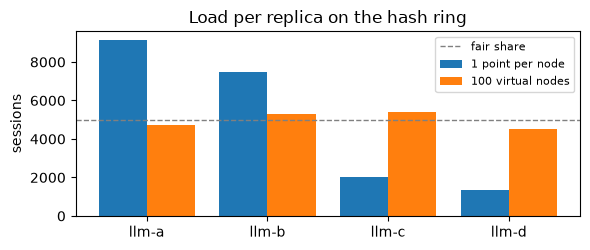

In [20]:
fig, ax = plt.subplots(figsize=(6, 2.6))
x = np.arange(len(nodes))
ax.bar(x - 0.2, [loads[1][n] for n in nodes], 0.4, label="1 point per node")
ax.bar(x + 0.2, [loads[100][n] for n in nodes], 0.4, label="100 virtual nodes")
ax.axhline(len(keys) / len(nodes), color="gray", ls="--", lw=1, label="fair share")
ax.set_xticks(x, nodes); ax.set_ylabel("sessions"); ax.set_title("Load per replica on the hash ring")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**What just happened?** With one point per node, the ring's arcs have random lengths, so one replica gets far more than its share. With 100 virtual nodes the arcs average out, and adding a 5th node moved roughly 1/5 of the keys (exactly the share the new node should take), versus about 80% with `% N`. With a single point per node, how many keys move is luck: here very few, which means the new replica sits almost idle.

### 8.2 Hot keys

Even a perfect hash cannot split **one** very popular key: the system prompt everyone shares, a viral document, one huge tenant. Fixes:
- **Replicate the hot key** to several nodes and read from any (fine for read-heavy data like a shared prompt-prefix cache).
- **Key salting:** write `hot#0 ... hot#7` and spread writes; readers combine them (fine for counters).
- **Local in-process cache** for the hottest few keys with a short TTL.
- **Per-tenant limits** and **dedicated shards** for the biggest customers.

### 8.3 Distributed cache invalidation

The cache patterns (cache-aside, write-through, TTL, stampede) are in [system design fundamentals, section 3](../23_Software_Engineering/09_system_design_fundamentals.ipynb). Across many nodes, the hard part is **telling every cache** that data changed.

| Approach | How | Trade-off |
|---|---|---|
| TTL only | entries expire after N seconds | simple; stale for up to N seconds |
| Delete on write | writer updates the DB, then **deletes** (not sets) the cache key | a race can still put an old value back; add a short TTL as a safety net |
| Versioned keys | key includes a version: `rag:answer:{doc_id}:v{doc_version}` | old entries are never read again, they just expire; very robust |
| Pub/sub invalidation | writer publishes "doc 17 changed" (ideally via the outbox); every node drops its local copy | fast; needs a reliable event path |
| Lease / single-flight | only one node refills a missing key, others wait | stops stampedes on hot keys |

**AI example:** a semantic cache of RAG answers must be invalidated when a **source document** changes. Store the document IDs and versions with each cached answer, and use versioned keys or pub/sub on "document updated" events.

### 8.4 Rate limiting across nodes

You have 4 API servers behind a load balancer and want "100 requests per minute per API key". If each server keeps its **own** counter, the real limit becomes 400. Here is what each option allows for one client sending 600 requests.

In [21]:
LIMIT, SERVERS, REQUESTS = 100, 4, 600
rng = random.Random(SEED)

def simulate(policy, sticky=False):
    local = [0] * SERVERS; shared = 0; allowed = 0
    for _ in range(REQUESTS):
        s = 0 if sticky else rng.randrange(SERVERS)        # which server the load balancer picks
        if policy == "local full limit":   ok = local[s] < LIMIT
        if policy == "local limit / N":    ok = local[s] < LIMIT // SERVERS
        if policy == "shared counter":     ok = shared < LIMIT     # e.g. an atomic Redis INCR or Lua script
        if ok: local[s] += 1; shared += 1; allowed += 1
    return allowed

for policy in ("local full limit", "local limit / N", "shared counter"):
    print(f"{policy:17}: spread traffic -> {simulate(policy):>3} allowed | all traffic on one server -> {simulate(policy, sticky=True):>3} allowed")

local full limit : spread traffic -> 400 allowed | all traffic on one server -> 100 allowed
local limit / N  : spread traffic -> 100 allowed | all traffic on one server ->  25 allowed
shared counter   : spread traffic -> 100 allowed | all traffic on one server -> 100 allowed


**What just happened?** Purely local limits let 4x too much through. Splitting the limit by N is correct only when traffic is perfectly spread; with sticky traffic the client gets only 25. A **shared counter** in a fast store (Redis, with an atomic `INCR` or a Lua script so two servers cannot both read "99") is exact, at the cost of a network round trip per request. Large systems mix both: local buckets that sync with the shared store every few hundred milliseconds. For LLM APIs, count **tokens**, not just requests. Decide what happens if the shared store is down: **fail open** (allow) or **fail closed** (deny; usually right for expensive GPU calls).

### 8.5 Bulkheads and friends (pointer)

**Bulkheads** split resources into separate pools so one overloaded part cannot sink the rest (like watertight compartments in a ship): for example, separate worker pools and GPU queues for the chat product and for batch jobs, so a huge batch upload cannot starve live chat. Bulkheads, **circuit breakers**, retries with backoff and jitter, and timeouts are simulated in [system design fundamentals, section 6](../23_Software_Engineering/09_system_design_fundamentals.ipynb) and applied to LLM calls in [notebook 09](09_ai_system_design_for_llm_applications.ipynb).

## 9. Multi-region and active-active

A **region** is a separate data-centre area (for example `eu-west`, `us-east`). Running in more than one protects against a whole region going down and puts servers closer to users.

Two numbers frame every multi-region design:
- **RPO** (Recovery Point Objective): how much recent data you may lose in a disaster ("up to 5 minutes of writes").
- **RTO** (Recovery Time Objective): how long until you are serving again ("within 15 minutes").

| Set-up | How | RPO / RTO | Main difficulty |
|---|---|---|---|
| Backup and restore | copies of data in another region | hours / hours | slow; test restores regularly |
| **Active-passive** (warm standby) | one region serves; another has replicated data and a small fleet ready | seconds-minutes / minutes | failover automation, DNS switch, avoiding split brain (both thinking they are primary) |
| **Active-active, read local / write home** | every region serves reads; each user's writes go to their "home" region | small / small | routing users to their home region |
| **Active-active, write anywhere** | every region accepts writes | ~0 / ~0 | **conflicting writes**: needs vector clocks, CRDTs or last-write-wins (with the clock problem of section 1), or a globally consistent database (Spanner, CockroachDB) that pays cross-region latency on writes |

Before you sign up for active-active, try back-of-envelope latency: a write that must be confirmed in two continents costs a round trip of the order of 100 ms (illustrative; it depends on the distance).

**AI-specific notes:**
- **Stateless inference is easy to run active-active**: the model weights are read-only, so every region can serve. The hard parts are the **stateful** pieces: conversation history, user memory, the vector index, feedback.
- **Vector indexes** are usually rebuilt or replicated per region from the same source (document store + outbox events), rather than written in two places.
- **GPU capacity** differs per region; the router needs to know which regions actually have free accelerators, and to fail over to a smaller fallback model when they do not.
- **Data residency** (for example EU users' data must stay in the EU) can forbid replicating some data at all. Design the partitioning by region first.

For the **deploy** side (blue/green, canary, shadow, feature flags), see [16_Deployment/05](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb). In a multi-region set-up, roll out one region at a time: a canary **region** is a strong safety net.

## 10. Infrastructure as Code (IaC)

### 10.1 What and why

**What it is:** **Infrastructure as Code** means describing your servers, networks, buckets, GPU node pools, databases and permissions in **text files** kept in Git, and letting a tool create or change the real cloud resources to match.

**Simple analogy:** a recipe instead of cooking from memory. Anyone can follow it, you can review changes to it, and you can cook the same dish again in a new kitchen (a new region, a staging environment).

**Why AI teams care:** GPU clusters, model buckets, vector databases, IAM roles for agents, and networking are expensive and easy to misconfigure. IaC makes them **reviewable** (pull requests), **repeatable** (identical staging and production), **auditable** (Git history) and **recoverable** (rebuild a region from code).

### 10.2 Key ideas

- **Declarative vs imperative.** Declarative: you describe the **end state** ("a bucket named X with versioning on") and the tool works out the steps. Imperative: you write the steps ("create bucket, then enable versioning"). Terraform, CloudFormation and Kubernetes manifests are declarative. Pulumi and CDK let you write normal code, but that code still builds a declarative **desired state** that the engine compares and applies.
- **State.** The tool keeps a **state file**: its record of which real resources it manages and their last known settings. It links "`gpu_pool.inference` in my code" to "node pool ID np-123 in the cloud".
- **Plan / apply.** `plan` compares desired state (code) with the real/recorded state and prints a **diff**: what would be created (+), changed (~), replaced (-/+), destroyed (-). Humans review the plan; `apply` executes it. Running apply twice in a row changes nothing (it is **idempotent**).
- **Drift.** Someone changes a resource by hand in the cloud console. The real world no longer matches the code. A `plan` (after refreshing from the cloud) shows the difference so you can either revert it or update the code.
- **Modules.** Reusable packages of resources, like functions: a "rag_stack" module with a bucket, a vector DB and an IAM role, used once per environment with different inputs.
- **Remote state and locking.** The state file is shared by the team, so it lives in a remote **backend** (an S3 / GCS bucket, Terraform Cloud / HCP, Pulumi Cloud) with **locking**, so two people cannot `apply` at the same time and corrupt it. This is exactly the distributed-lock problem of section 3.
- **Secrets** do not belong in the code or plain-text state; use a secrets manager and mark values as sensitive.

### 10.3 The tools

| Tool | Language | State | Notes |
|---|---|---|---|
| **Terraform** (HashiCorp) | HCL (a config language) | state file, local or remote backend | huge provider ecosystem, multi-cloud. Its licence changed in 2023; the community fork **OpenTofu** (Linux Foundation) is largely compatible |
| **Pulumi** | Python, TypeScript, Go, C#, Java | Pulumi Cloud or self-managed backend | real loops, functions and tests in a general language |
| **AWS CloudFormation** | YAML / JSON templates | managed by AWS ("stacks") | AWS only; no state file to manage yourself |
| **AWS CDK** | TypeScript, Python, ... | compiles ("synthesizes") to CloudFormation | code on top of CloudFormation |
| Kubernetes manifests + Helm + GitOps | YAML | the cluster itself | for things **inside** the cluster; see [Helm and GitOps](../17_Docker/03_helm_and_gitops.ipynb) |

A common split: Terraform/Pulumi creates the **cloud** (network, cluster, GPU node pools, buckets, databases); Helm charts + a GitOps tool (ArgoCD, Flux) deploy the **apps** onto the cluster. **GitOps** extends the same loop: Git is the desired state, and a controller continuously plans and applies (and so fixes drift automatically).

### 10.4 What it looks like

Terraform (HCL), for a model-artifacts bucket and a GPU node pool on a managed Kubernetes cluster (shown for reading, not run here; resource names follow the Google Cloud provider):

```hcl
terraform {
  backend "gcs" {                       # remote state, shared and locked
    bucket = "acme-terraform-state"
    prefix = "rag-platform/prod"
  }
}

variable "max_gpu_nodes" { default = 4 }

resource "google_storage_bucket" "model_artifacts" {
  name     = "acme-model-artifacts-prod"
  location = "EU"
  versioning { enabled = true }         # keep old model versions
}

resource "google_container_node_pool" "inference" {
  name    = "gpu-inference"
  cluster = google_container_cluster.main.id
  autoscaling {
    min_node_count = 1
    max_node_count = var.max_gpu_nodes
  }
  node_config {
    machine_type = "g2-standard-8"
    guest_accelerator {
      type  = "nvidia-l4"
      count = 1
    }
  }
}

module "rag_stack" {                    # a reusable module, used per environment
  source      = "./modules/rag_stack"
  environment = "prod"
  index_dims  = 768
}
```

Typical workflow: `terraform init` (download providers, connect the backend) -> `terraform plan` -> review -> `terraform apply`. In CI, the plan is posted on the pull request and apply runs after merge.

The same idea in Pulumi (Python), where loops and functions are just Python:

```python
import pulumi
import pulumi_gcp as gcp

config = pulumi.Config()
max_gpu_nodes = config.get_int("maxGpuNodes") or 4

bucket = gcp.storage.Bucket("model-artifacts",
    location="EU",
    versioning={"enabled": True})

# one GPU node pool per model size, created in a normal Python loop
for size, machine in {"small": "g2-standard-8", "large": "a2-highgpu-1g"}.items():
    gcp.container.NodePool(f"gpu-{size}",
        cluster=cluster.id,                       # 'cluster' defined elsewhere in the program
        autoscaling={"min_node_count": 0, "max_node_count": max_gpu_nodes},
        node_config={"machine_type": machine})

pulumi.export("artifacts_bucket", bucket.url)
```

Run with `pulumi preview` (the plan) and `pulumi up` (apply). Exact resource arguments change between provider versions, so check the provider docs before copying.

### 10.5 A toy plan / apply / drift engine

To see what these tools do inside, here is a tiny engine. `desired` is our "code", `cloud` is the real world (a dict standing in for the cloud API), and `state` is the tool's record. Some fields cannot be changed in place (like a bucket's region), so changing them forces **replace** (destroy then create).

In [22]:
IMMUTABLE = {"region", "dims"}         # changing these needs destroy + create

def plan(desired, actual):
    """Compare desired vs actual resources and return a list of (action, address, details)."""
    steps = []
    for addr, want in desired.items():
        have = actual.get(addr)
        if have is None:
            steps.append(("+ create", addr, want)); continue
        diff = {k: (have.get(k), v) for k, v in want.items() if have.get(k) != v}
        if diff:
            action = "-/+ replace" if IMMUTABLE & diff.keys() else "~ update"
            steps.append((action, addr, diff))
    for addr in actual:
        if addr not in desired:
            steps.append(("- destroy", addr, actual[addr]))
    return steps

def show(steps):
    if not steps: print("  No changes. Infrastructure matches the configuration.")
    for action, addr, details in steps:
        print(f"  {action:12} {addr:28} {details}")

In [23]:
def apply(steps, cloud, state):
    for action, addr, details in steps:
        if action == "- destroy":
            cloud.pop(addr); state.pop(addr)
        elif action == "~ update":
            for k, (_, new) in details.items(): cloud[addr][k] = new
            state[addr] = copy.deepcopy(cloud[addr])
        else:  # create or replace: build it from the desired settings
            cloud[addr] = copy.deepcopy(desired[addr]); state[addr] = copy.deepcopy(cloud[addr])
    print(f"  Apply complete: {len(steps)} change(s).")

def refresh(state, cloud):
    """Read the real cloud and update the state (this is how drift becomes visible)."""
    for addr in list(state):
        if addr in cloud: state[addr] = copy.deepcopy(cloud[addr])
        else: state.pop(addr)

desired = {
    "bucket.model_artifacts":  {"region": "eu", "versioning": True},
    "gpu_pool.inference":      {"machine": "g-l4", "min_nodes": 1, "max_nodes": 4},
    "vector_db.rag_index":     {"dims": 768, "replicas": 2},
}
cloud, state = {}, {}
print("1) first plan:"); p = plan(desired, state); show(p)
print("2) apply:");      apply(p, cloud, state)
print("3) plan again (should be empty, apply is idempotent):"); show(plan(desired, state))

1) first plan:
  + create     bucket.model_artifacts       {'region': 'eu', 'versioning': True}
  + create     gpu_pool.inference           {'machine': 'g-l4', 'min_nodes': 1, 'max_nodes': 4}
  + create     vector_db.rag_index          {'dims': 768, 'replicas': 2}
2) apply:
  Apply complete: 3 change(s).
3) plan again (should be empty, apply is idempotent):
  No changes. Infrastructure matches the configuration.


In [24]:
print("4) someone raises max_nodes to 12 in the cloud console during an incident (drift)")
cloud["gpu_pool.inference"]["max_nodes"] = 12
print("   plan WITHOUT refresh (trusting the old state file):"); show(plan(desired, state))
refresh(state, cloud)
print("   plan AFTER refresh:"); show(plan(desired, state))

print("\n5) code change: new embedding model with 1024 dims, and we drop the replicas to 1")
desired["vector_db.rag_index"] = {"dims": 1024, "replicas": 1}
del desired["bucket.model_artifacts"]                # someone deleted the bucket block by mistake
show(plan(desired, state))

4) someone raises max_nodes to 12 in the cloud console during an incident (drift)
   plan WITHOUT refresh (trusting the old state file):
  No changes. Infrastructure matches the configuration.
   plan AFTER refresh:
  ~ update     gpu_pool.inference           {'max_nodes': (12, 4)}

5) code change: new embedding model with 1024 dims, and we drop the replicas to 1
  ~ update     gpu_pool.inference           {'max_nodes': (12, 4)}
  -/+ replace  vector_db.rag_index          {'dims': (768, 1024), 'replicas': (2, 1)}
  - destroy    bucket.model_artifacts       {'region': 'eu', 'versioning': True}


**What just happened?**
- The first plan created three resources. The second plan was empty: applying the same code again changes nothing.
- The manual console change was **invisible** until we refreshed from the real cloud. (Real `terraform plan` refreshes by default; `-refresh=false` skips it, which is exactly the blind spot shown here.) After the refresh, the plan wants to set `max_nodes` back to 4. That is the decision point: revert the drift, or update the code to 12 if the change was right.
- Changing `dims` forces **replace**: the vector DB would be destroyed and recreated **empty**. Deleting the bucket block from the code would **destroy the bucket with all model artifacts**. This is why humans read plans, and why real tools offer guards like `prevent_destroy` (Terraform) or `protect` (Pulumi) on precious resources.

Finally, **state locking**. Two engineers (or two CI jobs) running apply at once could both read the same state and overwrite each other's changes. Remote backends take a lock first:

In [25]:
class StateBackend:
    def __init__(self): self.lock_holder = None
    def lock(self, who):
        if self.lock_holder: return f"Error acquiring the state lock: held by {self.lock_holder}"
        self.lock_holder = who; return f"lock acquired by {who}"
    def unlock(self, who):
        if self.lock_holder == who: self.lock_holder = None

backend = StateBackend()
print("CI job #41 :", backend.lock("ci-job-41"))
print("alice      :", backend.lock("alice@laptop"), "-> she waits and retries after the job finishes")
backend.unlock("ci-job-41")
print("alice      :", backend.lock("alice@laptop"))

CI job #41 : lock acquired by ci-job-41
alice      : Error acquiring the state lock: held by ci-job-41 -> she waits and retries after the job finishes
alice      : lock acquired by alice@laptop


If a CI job dies while holding the lock, the lock stays until someone runs a "force unlock" after checking nothing is still running. Same lesson as section 3: a lock without a lease needs a human to clean up.

**When to use IaC:** anything that lives longer than an afternoon experiment, and all production. **When not to:** a one-off exploration in a sandbox account (but tear it down afterwards). Do not mix: once a resource is managed by IaC, change it only through IaC, or drift will bite you.

## 11. Back-of-envelope estimation for an AI system

The method and "numbers worth remembering" are in [system design fundamentals, section 1](../23_Software_Engineering/09_system_design_fundamentals.ipynb), and a full ML example is in [notebook 08](08_industry_system_design_case_study.ipynb). Here is one LLM-serving estimate. **All inputs are illustrative assumptions**, not benchmarks; in an interview, say your assumptions out loud like this.

In [26]:
assume = {
    "daily_active_users": 1_000_000,
    "messages_per_user_per_day": 10,
    "output_tokens_per_message": 300,
    "peak_to_average": 3,                 # traffic is bursty during the day
    "output_tokens_per_s_per_gpu": 2_000, # depends hugely on model size, batching and hardware
    "target_utilisation": 0.6,            # leave headroom for spikes and failover
}
a = assume
avg_qps  = a["daily_active_users"] * a["messages_per_user_per_day"] / 86_400
peak_qps = avg_qps * a["peak_to_average"]
peak_tok = peak_qps * a["output_tokens_per_message"]
gpus     = peak_tok / (a["output_tokens_per_s_per_gpu"] * a["target_utilisation"])
print(f"average messages/s : {avg_qps:,.0f}")
print(f"peak messages/s    : {peak_qps:,.0f}")
print(f"peak output tok/s  : {peak_tok:,.0f}")
print(f"GPUs needed (peak) : {np.ceil(gpus):,.0f}  -> per region, if each region must survive alone, roughly double it")

average messages/s : 116
peak messages/s    : 347
peak output tok/s  : 104,167
GPUs needed (peak) : 87  -> per region, if each region must survive alone, roughly double it


**What just happened?** Ten million messages a day is only about a hundred messages per second on average, but token generation, not requests, sets the GPU count. The last line connects back to section 9: active-active with full failover capacity costs about twice the hardware.

## 12. Recap

| Pattern | One-line idea | AI example | Watch out for |
|---|---|---|---|
| Lamport clock | counter that respects cause and effect | order agent tool-call events across services | does not detect concurrency |
| Vector clock | per-node counters; detects concurrent writes | prompt template edited in two regions | grows with number of nodes |
| Raft / consensus | majority agrees on a leader and an ordered log | etcd behind Kubernetes; scheduler metadata | use a library/service, never hand-roll |
| Leader election | exactly one active instance | one GPU scheduler leader | old leader waking up: terms + fencing |
| Lease lock | lock that expires unless renewed | lock around index rebuilds | paused holders |
| Fencing token | increasing number checked by storage | reject a stale index-pointer write | storage must check it |
| Redlock | Redis lock on a majority of nodes | dedupe re-embedding work (efficiency) | no fencing; timing assumptions |
| Idempotency key | unique ID makes retries safe | "start fine-tune" retried by the client | store key and effect atomically |
| Saga | steps + compensations, no global transaction | reserve GPUs -> snapshot -> charge -> launch | no isolation; idempotent compensations |
| Outbox | event saved in same DB transaction, relayed later | "document added" -> embed for RAG | duplicates: idempotent consumers |
| CQRS | separate write and read models | model registry dashboard | read side lags |
| Event sourcing | store events, derive state | model registry audit, agent action log | replay cost, schema changes, GDPR |
| Service discovery | registry of healthy instances (leases) | find GPU inference replicas | stale entries until TTL |
| Sidecar / mesh | proxy next to each service for TLS, retries, metrics | mTLS + token metrics on LLM pods | extra latency and ops work |
| API gateway | one front door for cross-cutting concerns | auth + token quotas | business logic creeping in |
| BFF | one backend per client type | chat UI (SSE) vs batch API | duplicated logic |
| Strangler fig | migrate piece by piece behind a router | old model API -> new LLM service | data sync between old and new |
| Consistent hashing | ring + virtual nodes; few keys move | session -> replica with warm KV cache | hot keys still need replication |
| Cache invalidation | TTL, delete-on-write, versioned keys, pub/sub | semantic cache vs changed documents | races; use versioned keys |
| Distributed rate limit | shared atomic counter (+ local buckets) | tokens per minute per API key | fail open vs fail closed |
| Bulkhead | separate pools per workload | batch jobs cannot starve live chat | idle capacity |
| Multi-region | active-passive or active-active | inference everywhere, state partitioned | conflicts, residency, 2x GPUs |
| IaC | desired state in Git; plan, review, apply | GPU node pools, buckets, vector DB | drift, destroy/replace in plans, state locking |

## 13. Interview questions

**Q1. You run 3 replicas of a GPU job scheduler. How do you make sure only one assigns GPUs?**
A: Leader election through a consensus-backed store (etcd, ZooKeeper, Consul, or a Kubernetes Lease). The leader renews its lease; if it dies, another replica takes over after the lease expires. Every assignment carries the leader's **fencing token** (term or lease revision), and the component that records assignments rejects lower tokens, so a paused old leader cannot double-assign. Use 3 or 5 nodes for the consensus store so a majority survives failures.

**Q2. Why do random election timeouts matter in Raft?**
A: If all followers time out together, each votes for itself and no one gets a majority (split vote), which can repeat forever. Random timeouts make one node usually start first and win before the others wake up.

**Q3. We already use a lock with a TTL. Why would we need fencing tokens?**
A: A holder can pause (GC, VM migration) longer than the TTL, lose the lock without knowing, and then write. Only the storage can detect that, by comparing the write's token with the highest it has seen. Checking the lock before writing does not help because the pause can happen after the check.

**Q4. Is Redlock safe?**
A: It is debated. Kleppmann argued it gives no fencing token and depends on timing assumptions, so it is unsafe for correctness-critical locks; antirez argued it is fine under its assumptions. A practical answer: fine for efficiency locks; for correctness use a consensus-backed lock with fencing, or avoid the lock with an atomic conditional write.

**Q5. A user uploads a document; it must become searchable in RAG. How do you make sure no upload is ever "saved but never indexed"?**
A: Transactional outbox: write the document row and a "DocumentAdded" outbox row in the same DB transaction. A relay (polling or CDC) publishes outbox rows to a queue at least once. The embedding worker is idempotent (dedupe by event ID or upsert by doc ID). Add a DLQ and an alert for poison messages, and a periodic reconciliation job that compares documents vs index.

**Q6. Saga or two-phase commit for "reserve quota, charge credits, launch job"?**
A: Saga. The steps span services (and maybe third-party billing) that do not share a transaction manager, and 2PC blocks when the coordinator fails. Use orchestration (a workflow engine) for clarity, give every step an idempotent compensation, and accept that intermediate states are visible.

**Q7. How would you migrate from a legacy model API to a new LLM-based service without downtime?**
A: Strangler fig: a router (gateway/ingress) in front of both; migrate endpoint by endpoint; shadow traffic and offline evals first; then canary by a stable hash of user ID (1% -> 10% -> 50% -> 100%) watching errors, latency, cost and quality; instant rollback by lowering the share; sync data via CDC/outbox; delete the legacy path at the end.

**Q8. API gateway vs BFF?**
A: The gateway is one front door for cross-cutting concerns (auth, rate limits, routing, TLS). A BFF is a backend per client type that shapes data for that client (chat UI with SSE streaming and citations vs a batch client with bulk jobs and webhooks). They are usually combined: gateway in front, BFFs behind.

**Q9. Rate limit "1M tokens per minute per API key" across 20 API servers.**
A: Shared counter (token bucket or sliding-window counter) in Redis, updated atomically (Lua script), keyed by API key and sharded across Redis nodes; reserve estimated tokens before the call and correct with actual usage after. For very high volume, local buckets that sync periodically. Decide fail-open vs fail-closed; for expensive GPU calls usually fail closed with a small local allowance.

**Q10. What is drift in Terraform, and how do you handle it?**
A: The real resource no longer matches code and state, usually because of a manual change. `terraform plan` (which refreshes from the cloud) shows it. Either revert by applying, or update the code if the change was right. Prevent it with least-privilege console access, GitOps-style regular plans in CI that alert on drift, and remote state with locking so applies do not overlap.

**Q11. Design a chat assistant to run active-active in two regions. What is hard?**
A: Inference is stateless and easy to run in both. The hard parts: conversation history and memory (home-region per user, or a multi-region database), the vector index (rebuild per region from the same event stream), conflicting edits (vector clocks/CRDTs or single-writer per user), data residency, and capacity: each region must hold the other's peak load in a failover, so roughly 2x GPUs.

## 14. Further reading

**Consensus and clocks**
- Diego Ongaro and John Ousterhout, "In Search of an Understandable Consensus Algorithm" (the Raft paper), USENIX ATC 2014. The Raft website, https://raft.github.io, has the paper and an interactive visualization.
- Leslie Lamport, "Time, Clocks, and the Ordering of Events in a Distributed System", Communications of the ACM, 1978.
- Leslie Lamport, "Paxos Made Simple", 2001.
- Mike Burrows, "The Chubby lock service for loosely-coupled distributed systems", OSDI 2006.
- Hunt et al., "ZooKeeper: Wait-free coordination for Internet-scale systems", USENIX ATC 2010.

**Locks**
- Martin Kleppmann, "How to do distributed locking" (blog post, 2016), https://martin.kleppmann.com/2016/02/08/how-to-do-distributed-locking.html
- Salvatore Sanfilippo (antirez), "Is Redlock safe?" (reply blog post, 2016), and the Redis documentation page on distributed locks.

**Books**
- Martin Kleppmann, *Designing Data-Intensive Applications* (O'Reilly, 2017): chapters on replication, partitioning, "The Trouble with Distributed Systems" (process pauses, clocks, fencing tokens) and "Consistency and Consensus".
- Sam Newman, *Building Microservices* (2nd ed., O'Reilly, 2021) and *Monolith to Microservices* (O'Reilly, 2019): strangler fig, BFF, sagas, migration patterns.

**Patterns**
- Martin Fowler, "StranglerFigApplication" (bliki), https://martinfowler.com/bliki/StranglerFigApplication.html
- Sam Newman, "Backends For Frontends" pattern article, https://samnewman.io/patterns/architectural/bff/
- Martin Fowler, "CQRS" and "Event Sourcing" articles on martinfowler.com.
- Chris Richardson, microservices.io pattern pages: Saga, Transactional outbox, CQRS, Event sourcing, API gateway / BFF, Service discovery.
- Hector Garcia-Molina and Kenneth Salem, "Sagas", SIGMOD 1987.

**Infrastructure as Code**
- Terraform documentation (HashiCorp), https://developer.hashicorp.com/terraform/docs (state, backends, state locking, `plan`, modules).
- OpenTofu documentation, https://opentofu.org/docs/
- Pulumi documentation, https://www.pulumi.com/docs/
- AWS CloudFormation and AWS CDK developer guides (AWS documentation).

**Overviews used for the coverage check**
- donnemartin/system-design-primer, ByteByteGo system-design-101, ashishps1/awesome-system-design-resources (GitHub), and the roadmap.sh system design roadmap.

**In this repo**
- [System design fundamentals](../23_Software_Engineering/09_system_design_fundamentals.ipynb), [distributed databases](../13_Databases/00_dbms_fundamentals/09_distributed_databases_warehousing_and_security.ipynb), [stream processing](../13_Databases/06_data_engineering/04_stream_processing_from_scratch.ipynb), [message queues](../16_Deployment/message_queues/01_message_queues.ipynb), [safe model rollout](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb), [Helm and GitOps](../17_Docker/03_helm_and_gitops.ipynb), [Kubernetes](../17_Docker/kubernetes/01_kubernetes.ipynb), [AI system design for LLM apps](09_ai_system_design_for_llm_applications.ipynb).